# Retail Churn Feature Store: walkthrough

**Problem:** every retail model was rebuilding the same churn features from scratch, each with slightly different logic.
**Solution:** one validated feature layer with **48 features in 7 behavioural groups**, built from **six source tables joined through the account master**, over a **12-month observation window**.

*Synthetic source tables. The real store was built in Oracle SQL on a bank's core warehouse.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
import subprocess, sys, json, pandas as pd
from IPython.display import Image, display, Markdown
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True, capture_output=True)
from src.feature_store import connect, build, grain_check, join_integrity, range_and_null_check
from src.registry import FEATURES, GROUPS
con = connect()
pd.DataFrame({t: [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]] for t in
              ["customer_master","account_master","txn_monthly","balance_monthly","channel_monthly","geo_monthly"]}, index=["rows"]).T

,rows
customer_master,15000
account_master,28109
txn_monthly,554745
balance_monthly,796239
channel_monthly,816619
geo_monthly,550551


## 1. Why the account master is the hub, and the bug it causes
Transactions and balances live at **account** level, but churn is a **customer** decision. If you join without rolling up to the customer, every multi-account customer turns into several *pseudo-replicated* rows:

In [2]:
con.execute("""
SELECT COUNT(*) AS rows_naive_join, COUNT(DISTINCT am.customer_id) AS customers
FROM txn_monthly t JOIN account_master am USING (account_id) WHERE t.month_idx = 17
""").df()

,rows_naive_join,customers
0,19576,15000


Every feature group in `sql/features/` aggregates to `customer_id` through the account master, and `sql/validation/v1_grain_check.sql` makes sure each group returns exactly one row per customer.

## 2. Build the store for one snapshot

In [3]:
fs = build(con, 18)
print(fs.shape[0], "customers x", len(FEATURES), "features")
pd.Series({GROUPS[g]: sum(f.startswith(g+'_') for f in FEATURES) for g in GROUPS}, name="features").to_frame()

11162 customers x 48 features


,features
Transactional behaviour,10
Balance & product holding,8
Channel sentiment,6
Geo-behavioural,5
Life-stage & demographic,6
Network & relationship,6
Risk-scoring layer,7


## 3. Graded target structure
A single binary label throws information away, so the store carries three:
* `churn_flag`: dormant for 90+ days (no transactions in the next 3 months)
* `early_warning_flag`: activity collapses in the first 45–60 days, the softer and earlier label used for outreach
* `surv_months` / `surv_event`: a survival label for time-to-dormancy models

In [4]:
fs[['churn_flag','early_warning_flag','surv_event']].mean().round(4).to_frame('rate')

,rate
churn_flag,0.0186
early_warning_flag,0.0233
surv_event,0.1648


## 4. Validation suite

In [5]:
display(grain_check(con))
display(join_integrity(con))
r = range_and_null_check(con)
print(f"null / range checks passed: {r.ok.sum()}/{len(r)}")

,table_name,rows,customers,ok
0,population,11162,11162,True
1,g1_transactional,11162,11162,True
2,g2_balance_product,11162,11162,True
3,g3_channel_sentiment,11162,11162,True
4,g4_geo_behavioural,11162,11162,True
5,g5_lifestage,11162,11162,True
6,g6_network_relationship,11162,11162,True
7,g7_risk_layer,11162,11162,True
8,feature_store,11162,11162,True


,check_name,failures,ok
0,txn rows without account,0,True
1,balance rows without account,0,True
2,accounts without customer,0,True
3,channel rows for unknown customer,0,True


null / range checks passed: 48/48


In [6]:
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
pd.read_csv("reports/validation_drift_psi.csv").head(5)

,feature,grp,psi,status
0,g1_months_since_peak,g1,0.366253,drift
1,g1_txn_trend_3v9,g1,0.080425,stable
2,g6_counterparties_trend,g6,0.037963,stable
3,g5_tenure_months,g5,0.017469,stable
4,g4_branch_visits_12m,g4,0.014119,stable


The drift check (PSI between the month-15 and month-18 snapshots) flags `g1_months_since_peak`. That is **seasonality** (the December peak moves relative to each snapshot), not a pipeline bug. This is exactly the kind of thing a PSI monitor is there to surface before a model quietly degrades.

## 5. Do the features carry signal?
The store is trained on month 15 and tested on month 18, then each group is removed in turn to see how much signal is **unique** to it.

,churn_flag,early_warning_flag
AUC (all 48),0.7786,0.7663
test rate,0.0186,0.0233


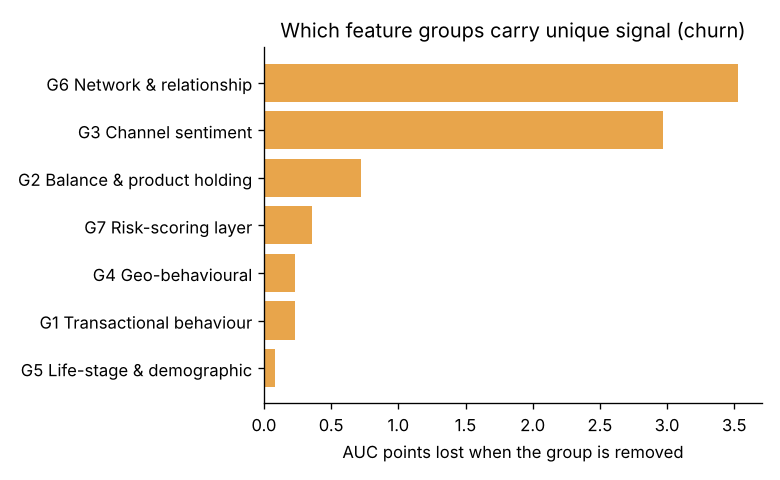

In [7]:
m = json.load(open("reports/metrics.json"))
display(pd.DataFrame({k: {"AUC (all 48)": v["auc_all_48"], "test rate": v["rate_test"]} for k, v in m["models"].items()}))
display(Image("reports/figures/group_ablation.png", width=560))

**Network & relationship** (salary credits, transfers to own accounts elsewhere) and **channel sentiment** carry the most signal that no other group duplicates. The rule layer (G7) adds little on top of a model that already sees its inputs, but it is what makes the output readable for a retention team:

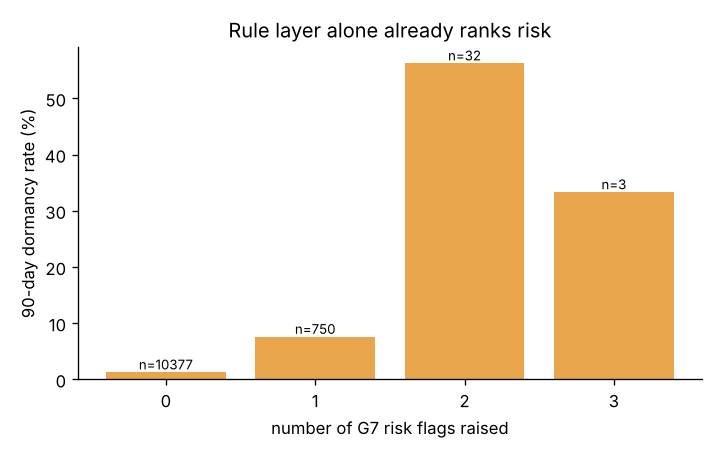

In [8]:
display(Image('reports/figures/flags_lift.png', width=520))

In [9]:
display(Markdown(open('docs/feature_dictionary.md').read()[:2500] + '\n\n*... see docs/feature_dictionary.md*'))

# Feature dictionary

Generated from `src/registry.py`. 48 features in 7 groups, computed over a 12-month observation window.

## G1 · Transactional behaviour (10)

| Feature | Description | Expected range |
|---|---|---|
| `g1_txn_cnt_12m` | Customer-initiated transactions, last 12 months | 0 – ∞ |
| `g1_txn_cnt_3m` | Transactions, last 3 months | 0 – ∞ |
| `g1_txn_value_12m_log` | log(1 + inflow + outflow value), 12 months | 0 – 40 |
| `g1_avg_monthly_txn` | Average monthly transactions | 0 – ∞ |
| `g1_txn_trend_3v9` | Avg monthly txns last 3m / previous 9m (+1 smoothed) | 0 – ∞ |
| `g1_months_active_12m` | Months with at least one transaction | 0 – 12 |
| `g1_months_since_peak` | Months since the busiest month in the window | 1 – 12 |
| `g1_outflow_inflow_ratio_3m` | Outflow / inflow, last 3 months | 0 – ∞ |
| `g1_max_gap_months` | Longest run of inactive months | 0 – 11 |
| `g1_txn_cv` | Coefficient of variation of monthly transactions | 0 – ∞ |

## G2 · Balance & product holding (8)

| Feature | Description | Expected range |
|---|---|---|
| `g2_avg_balance_12m_log` | log(1 + average deposit balance), 12 months | 0 – 40 |
| `g2_balance_trend` | Slope of signed-log deposit balance per month | −∞ – ∞ |
| `g2_balance_3m_vs_12m` | Avg balance last 3m / avg balance 12m | −∞ – ∞ |
| `g2_min_balance_ratio` | Min monthly balance / average balance | −∞ – ∞ |
| `g2_n_accounts` | Number of accounts held | 1 – 20 |
| `g2_n_product_types` | Number of distinct product types | 1 – 5 |
| `g2_has_card` | Holds a card product | 0 – 1 |
| `g2_has_loan` | Holds a loan product | 0 – 1 |

## G3 · Channel sentiment (6)

| Feature | Description | Expected range |
|---|---|---|
| `g3_channel_success_rate_6m` | Digital success rate, 6m, volume-weighted + shrunk (k=20) | 0 – 1 |
| `g3_failed_txn_3m` | Failed digital attempts, last 3 months | 0 – ∞ |
| `g3_digital_share_12m` | Share of activity through digital channels | 0 – 1 |
| `g3_n_channels_used` | Distinct digital channels used | 0 – 4 |
| `g3_digital_trend_3v9` | Digital activity last 3m vs previous 9m | 0 – ∞ |
| `g3_css_score` | Channel Sentiment Score (0-100, 60/20/20) | 0 – 100 |

## G4 · Geo-behavioural (5)

| Feature | Description | Expected range |
|---|---|---|
| `g4_n_states_12m` | Distinct states with branch / ATM / POS activity | 0 – 37 |
| `g4_top_state_share` | Share of activity in the most-used state | 0 – 1 |
| `g4_relocated_flag` | Most-used state differs from account-opening state | 0 – 1 |
| `g4_branch_v

*... see docs/feature_dictionary.md*